## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


> -0.01. I would rather not get the aoritc balloon pump because the ATE is negative (meaning the mean of those who survived in the conservative group was greater than that of the invasive group).

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

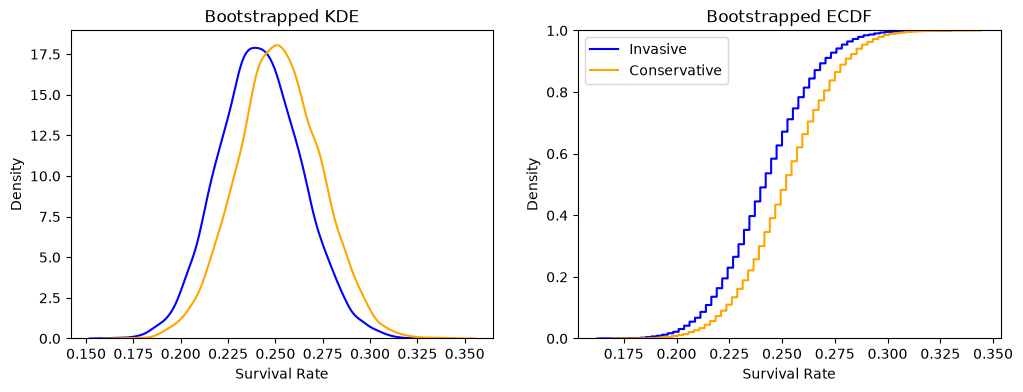

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

>It looks like at any point, the estimated survival rate for invasive is lower than that of conservative, and the KDE shows that the data are more concentrated at lower survival rates than conservative.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

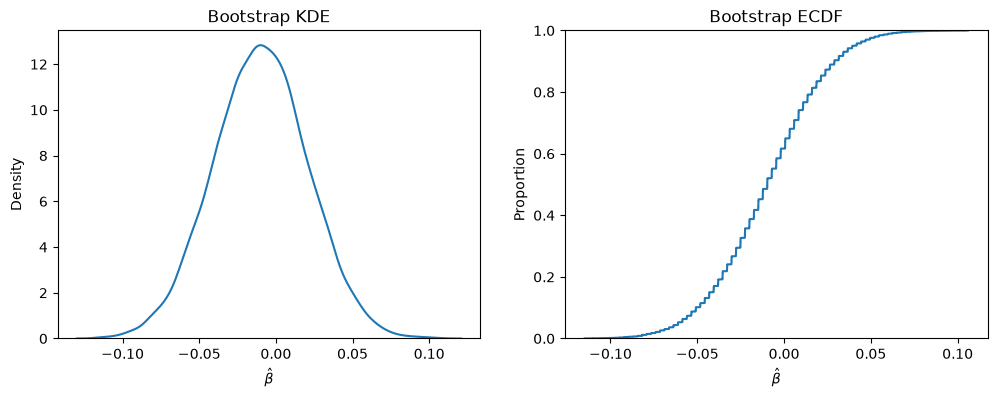

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


>The KDE does have roughly a bell shape that is centered slightly below 0. The range of values for this invervention are between -0.10 and 0.10, meaning that some samples showed a positive treatment effect and some showed a negative treatment effect, with the distribution of these treatment effects centered slightly below 0 (so just a little more of them are negative).

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [9]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06111361  0.03930942]
95% CI: [-0.07140318  0.04958557]
99% CI: [-0.08944425  0.07011767]


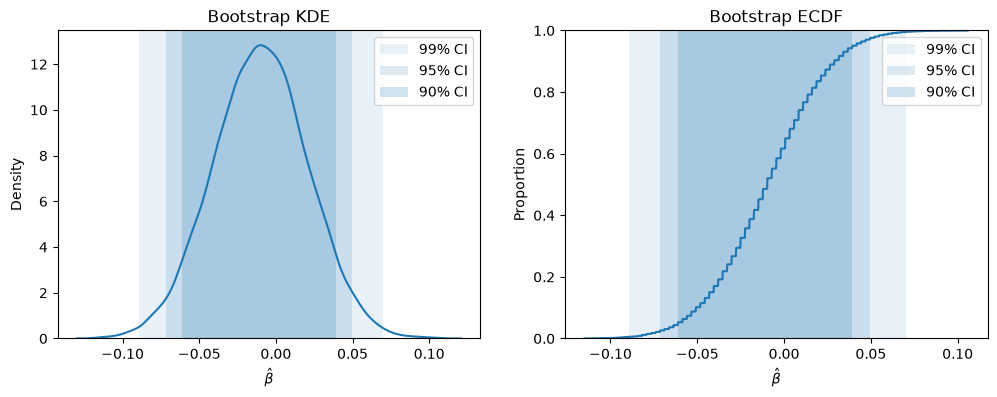

In [10]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

> 0 is in the confidence intervals. We fail to reject the null hypothesis that the ATE is 0 in all 3 of these confidence intervals because 0 falls within each one of them.

**6.** What have we learned about inserting balloons into hearts?

> We have learned that we are not sure if it is worse than conservative therapies, but our distributions on average had a slightly negatvie ATE which is evidence that it may actually be worse than conservative methods.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

## 1.

In [29]:
df = pd.read_csv('./data/diabetes.csv')
pd.crosstab(df['treatment'],df['outcome'])

outcome,failure,success
treatment,,
lifestyle,109,125
met,120,112
rosi,90,143


In [35]:
df2 = pd.get_dummies(df, columns =['outcome'],drop_first= True,dtype = int)
lifem = df2.loc[ df2['treatment'] == 'lifestyle', 'outcome_success'].mean()
metm = df2.loc[ df2['treatment'] == 'met', 'outcome_success'].mean()
rosim = df2.loc[ df2['treatment'] == 'rosi', 'outcome_success'].mean()

print(f'Success Proportions:\nLifestyle: {lifem:.2f}\nMet: {metm:.2f}\nRosi: {rosim:.2f}')

Success Proportions:
Lifestyle: 0.53
Met: 0.48
Rosi: 0.61


>The average outcome for Lifestyle is a success, the average outcome for Met is a failure, and the average outcome for Rosi is a success. These have proportions shown above.

## 2.

In [37]:
R = 10000

df_l = df2.loc[df['treatment']=='lifestyle',:]
df_m = df2.loc[df['treatment']=='met',:]
df_r = df2.loc[df['treatment']=='rosi',:]

outcome_l = []
outcome_m = []
outcome_r = []
ate_mr = []
ate_ml = []
ate_rl = []

for i in range(R):
    df_li= df_l.sample(frac=1.0,replace=True)
    df_mi= df_m.sample(frac=1.0,replace=True)
    df_ri= df_r.sample(frac=1.0,replace=True)

    oli = df_li['outcome_success'].mean()
    omi = df_mi['outcome_success'].mean()
    ori = df_ri['outcome_success'].mean()

    #met v rosie
    ate_mri = omi-ori
    #met v lifestyle
    ate_mli = omi-oli
    #rosi v lifestyle
    ate_rli = ori-oli

    outcome_l.append(oli)
    outcome_m.append(omi)
    outcome_r.append(ori)
    ate_mr.append(ate_mri)
    ate_ml.append(ate_mli)
    ate_rl.append(ate_rli)

## 3.

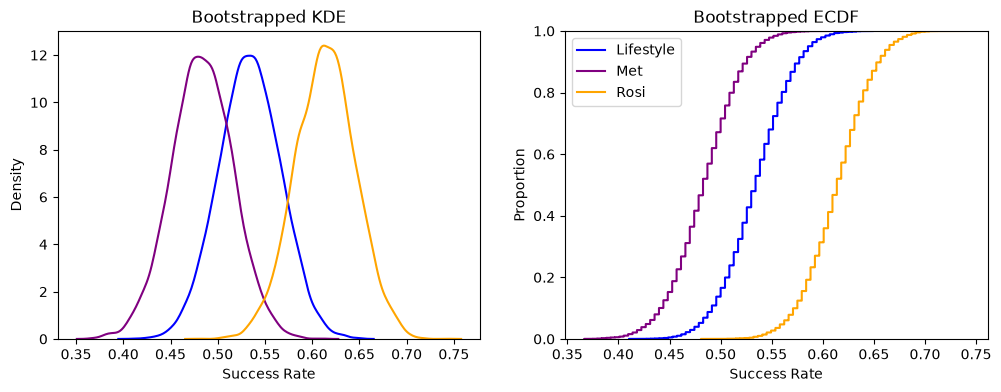

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_l, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_m, label='Met', color='purple', ax=ax[0])
sns.kdeplot(outcome_r, label='Rosi', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')


sns.ecdfplot(outcome_l, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_m, label='Met', color='purple', ax=ax[1])
sns.ecdfplot(outcome_r, label='Rosi', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

> It looks like the three treatments have a clear success ranking, with Rosi having the highest success rate at any proportion, followed by Lifestyle and then Met. Their KDE's show that the points are concentrated in a similar order, with Rosi being concentrated at the highest points followed by Lifestyle and then Met.

## 4.

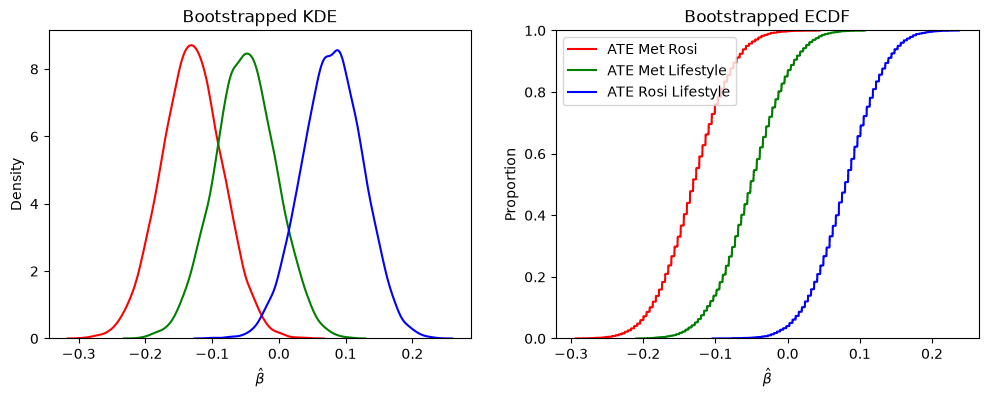

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_mr, label='ATE Met Rosi', color='red', ax=ax[0])
sns.kdeplot(ate_ml, label='ATE Met Lifestyle', color='green', ax=ax[0])
sns.kdeplot(ate_rl, label='ATE Rosi Lifestyle', color='blue', ax=ax[0]).set(title='Bootstrapped KDE', xlabel=r"$\hat{\beta}$", ylabel='Density')


sns.ecdfplot(ate_mr, label='ATE Met Rosi', color='red', ax=ax[1])
sns.ecdfplot(ate_ml, label='ATE Met Lifestyle', color='green', ax=ax[1])
sns.ecdfplot(ate_rl, label='ATE Rosi Lifestyle', color='blue', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel=r"$\hat{\beta}$", ylabel='Proportion')

plt.legend()
plt.show()

## 5.

CI 90% Met Rosi: -0.20 to -0.05
CI 90% Met Lifestyle: -0.13 to 0.03
CI 90% Rosi Lifestyle: 0.00 to 0.15

CI 95% Met Rosi: -0.22 to -0.04
CI 95% Met Lifestyle: -0.14 to 0.04
CI 95% Rosi Lifestyle: -0.01 to 0.17

CI 99% Met Rosi: -0.25 to -0.01
CI 99% Met Lifestyle: -0.17 to 0.07
CI 99% Rosi Lifestyle: -0.04 to 0.20


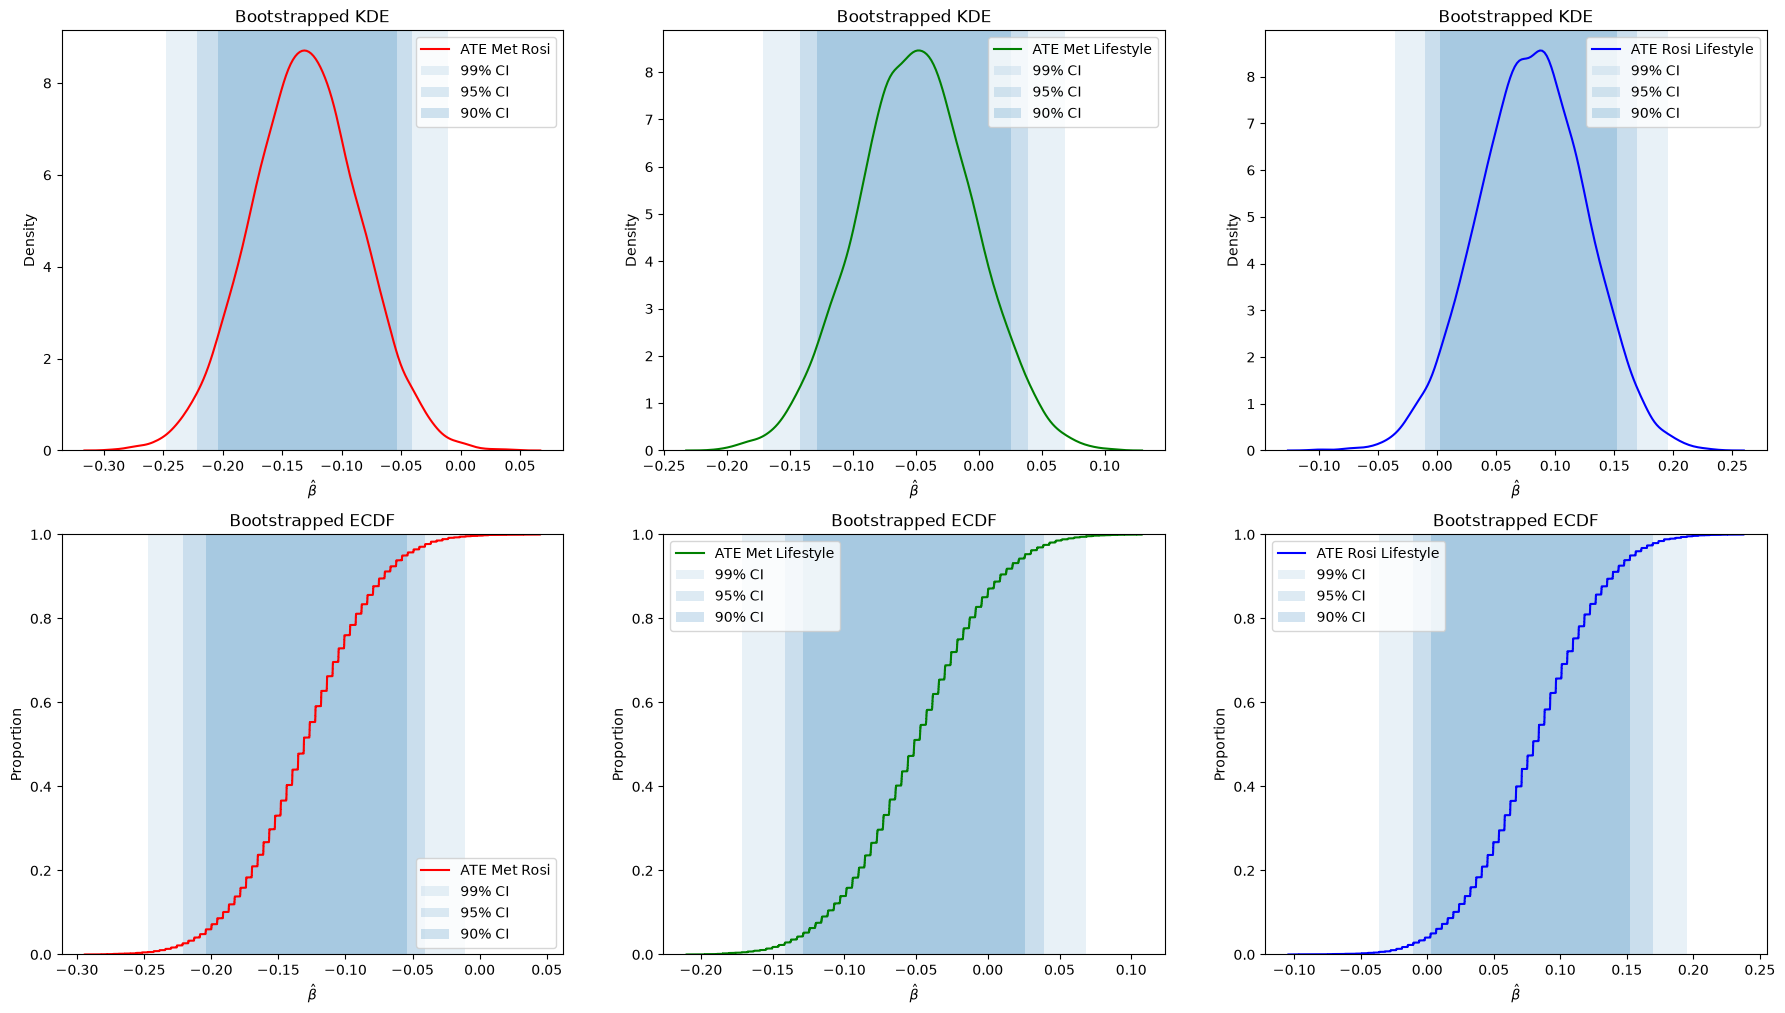

In [59]:
cimr90 = np.quantile(ate_mr, [.05, .95])
cimr95 = np.quantile(ate_mr, [.025, .975])
cimr99 = np.quantile(ate_mr, [.005, .995])

ciml90 = np.quantile(ate_ml, [.05, .95])
ciml95 = np.quantile(ate_ml, [.025, .975])
ciml99 = np.quantile(ate_ml, [.005, .995])

cirl90 = np.quantile(ate_rl, [.05, .95])
cirl95 = np.quantile(ate_rl, [.025, .975])
cirl99 = np.quantile(ate_rl, [.005, .995])

print(f'CI 90% Met Rosi: {cimr90[0]:.2f} to {cimr90[1]:.2f}')
print(f'CI 90% Met Lifestyle: {ciml90[0]:.2f} to {ciml90[1]:.2f}')
print(f'CI 90% Rosi Lifestyle: {cirl90[0]:.2f} to {cirl90[1]:.2f}\n')


print(f'CI 95% Met Rosi: {cimr95[0]:.2f} to {cimr95[1]:.2f}')
print(f'CI 95% Met Lifestyle: {ciml95[0]:.2f} to {ciml95[1]:.2f}')
print(f'CI 95% Rosi Lifestyle: {cirl95[0]:.2f} to {cirl95[1]:.2f}\n')

print(f'CI 99% Met Rosi: {cimr99[0]:.2f} to {cimr99[1]:.2f}')
print(f'CI 99% Met Lifestyle: {ciml99[0]:.2f} to {ciml99[1]:.2f}')
print(f'CI 99% Rosi Lifestyle: {cirl99[0]:.2f} to {cirl99[1]:.2f}')

fig, ax = plt.subplots(2, 3, figsize=(22, 12))

## KDES
sns.kdeplot(ate_mr, label='ATE Met Rosi', color='red', ax=ax[0,0]).set(title='Bootstrapped KDE', xlabel=r"$\hat{\beta}$", ylabel='Density')
ax[0,0].axvspan(cimr99[0], cimr99[1], alpha=0.10, label="99% CI")
ax[0,0].axvspan(cimr95[0], cimr95[1], alpha=0.15, label="95% CI")
ax[0,0].axvspan(cimr90[0], cimr90[1], alpha=0.20, label="90% CI")
ax[0,0].legend()

sns.kdeplot(ate_ml, label='ATE Met Lifestyle', color='green', ax=ax[0,1]).set(title='Bootstrapped KDE', xlabel=r"$\hat{\beta}$", ylabel='Density')
ax[0,1].axvspan(ciml99[0], ciml99[1], alpha=0.10, label="99% CI")
ax[0,1].axvspan(ciml95[0], ciml95[1], alpha=0.15, label="95% CI")
ax[0,1].axvspan(ciml90[0], ciml90[1], alpha=0.20, label="90% CI")
ax[0,1].legend()

sns.kdeplot(ate_rl, label='ATE Rosi Lifestyle', color='blue', ax=ax[0,2]).set(title='Bootstrapped KDE', xlabel=r"$\hat{\beta}$", ylabel='Density')
ax[0,2].axvspan(cirl99[0], cirl99[1], alpha=0.10, label="99% CI")
ax[0,2].axvspan(cirl95[0], cirl95[1], alpha=0.15, label="95% CI")
ax[0,2].axvspan(cirl90[0], cirl90[1], alpha=0.20, label="90% CI")
ax[0,2].legend()

## ECDFS
sns.ecdfplot(ate_mr, label='ATE Met Rosi', color='red', ax=ax[1,0]).set(title='Bootstrapped ECDF', xlabel=r"$\hat{\beta}$", ylabel='Proportion')
ax[1,0].axvspan(cimr99[0], cimr99[1], alpha=0.10, label="99% CI")
ax[1,0].axvspan(cimr95[0], cimr95[1], alpha=0.15, label="95% CI")
ax[1,0].axvspan(cimr90[0], cimr90[1], alpha=0.20, label="90% CI")
ax[1,0].legend()

sns.ecdfplot(ate_ml, label='ATE Met Lifestyle', color='green', ax=ax[1,1]).set(title='Bootstrapped ECDF', xlabel=r"$\hat{\beta}$", ylabel='Proportion')
ax[1,1].axvspan(ciml99[0], ciml99[1], alpha=0.10, label="99% CI")
ax[1,1].axvspan(ciml95[0], ciml95[1], alpha=0.15, label="95% CI")
ax[1,1].axvspan(ciml90[0], ciml90[1], alpha=0.20, label="90% CI")
ax[1,1].legend()

sns.ecdfplot(ate_rl, label='ATE Rosi Lifestyle', color='blue', ax=ax[1,2]).set(title='Bootstrapped ECDF', xlabel=r"$\hat{\beta}$", ylabel='Proportion')
ax[1,2].axvspan(cirl99[0], cirl99[1], alpha=0.10, label="99% CI")
ax[1,2].axvspan(cirl95[0], cirl95[1], alpha=0.15, label="95% CI")
ax[1,2].axvspan(cirl90[0], cirl90[1], alpha=0.20, label="90% CI")
ax[1,2].legend()

> The only statistically significant difference with 99, 95, and 90% confidence I found was the ATE of the Met vs Rosi treatments. It looks like Rosi is statistically significantly more effective than Met is. If we use a 90% confidence, then we can also say that the ATE of the Rosi vs Lifestyle treatments had a statistically significant outcome. It looks like with 90% confidence, Rosi is more effective than Lifestyle changes. Based off of these results it seems like Rosi is the most effective treatment method with statistical significance.

## 6.